# GSB 5544 — Topic 12.1: Project Exploration — NFL Running Backs and the Hall of Fame — SOLUTIONS
*The 20-minute opener with every blank filled, the answers to the discussion prompts, and instructor notes.*

> **Instructor note.** **Run of show (20 minutes).** Part 0 the idea and the five questions (2 min) · Part 1 ETV and SSVA, the two maps
> (3 min) · Part 2 Extract (3 min) · Part 3 Transform (5 min) · Part 4 Visualize, one figure per question (5 min) ·
> Part 5 how to improve the project (2 min). For 15 minutes skip 3.2 and Figure 4 and give Part 5 as homework.
> **The point to land:** a project is coherent when every cell is an E, a T or a V, and every figure answers a
> numbered question with a statistic you can name. Everything else is cut.
> **Why this project:** it is my own final-project idea at the outline stage, so the class sees the planning
> document and the first running version side by side, including what the data cannot answer yet.

## Part 0 — The idea in one paragraph

We want to know how **Hall of Fame running backs** compared with the *other* running backs who played at the same
time, and then use those comparisons to find **current and recently retired** players whose statistical profiles
look like a Hall of Famer's.

**The five project questions**

1. Which running backs, halfbacks and fullbacks are in the Pro Football Hall of Fame?
2. How did each Hall of Famer's rushing (and receiving) statistics compare with other running backs **in each season
   they played**?
3. What patterns show up across Hall of Fame careers: exceptional **peak** seasons, **sustained** performance, or both?
4. Which active or recently retired players show similar patterns at the same stage of their careers?
5. How much do the answers change with different statistics or a different **comparison group**?

**Key idea.** Compare a player with the other running backs in the same **season** *first*. A 1,200-yard season in a
year when the median qualified back gained 800 yards is 400 yards, or 50 %, above that season's median, and we can
also report the player's **percentile** among the qualifying backs that year. This makes comparisons more informative
across periods with different schedules and offensive styles. It does **not** remove every difference between eras.

## Part 1 — Two maps that make a project coherent

### ETV — every step is an Extraction, a Transformation or a Visualization

The project outline had thirteen steps. Label each one. (E = extract data from a source · T = transform it: clean,
join, filter, compute · V = visualize or tabulate for a reader.)

| # | Outline step | Stage |
|---|---|:---:|
| 1 | Set up the notebook: packages, data sources, analysis settings | — |
| 2 | Read the Wikipedia list of inductees and identify the running backs | **E** |
| 3 | Obtain player-season rushing and receiving statistics (permitted source) | **E** |
| 4 | Standardize columns and positions, resolve team changes, one row per player-season | **T** |
| 5 | Match each Hall of Famer to the correct player record (crosswalk) | **T** |
| 6 | Define each season's comparison group (≥ 50 carries) | **T** |
| 7 | Difference from the season median and percentile among contemporaries | **T** |
| 8 | Summarize Hall of Fame careers: typical, peak, longevity | **T** |
| 9 | Label players as inducted, active, retired-not-eligible, eligible | **T** |
| 10 | Compare active players with Hall of Famers at the same career stage | **T** |
| 11 | Tables and figures: within a season, across a career, current vs historical | **V** |
| 12 | Data checks, sensitivity checks, retrospective evaluation | **T** (and V) |
| 13 | Save results, state limitations, document next steps | — |

Three stages hide inside thirteen steps: **two** extractions, **eight** transformations, **one** visualization step
that should really be spread across the notebook, one figure per question. Steps 1 and 13 are bookkeeping.

### SSVA — every question is answered by a Summary Statistic, a Visualization, and an Analysis sentence

| Question | Summary statistic (the number) | Visualization (the figure) | Analysis (the sentence) |
|---|---|---|---|
| Q1 Who is in the Hall? | a count: 53 running backs, halfbacks and fullbacks | a table, not a chart | *N* Hall of Famers; *n* of them played in the seasons we can observe |
| Q2 Player vs that season | season **median** and the player's **percentile** | **histogram** of one season's rushing yards with the median and the player marked | "In 2006 Tomlinson gained 1,815 yards, 1,070 above the median" |
| Q3 Peak or sustained? | median season percentile; **share** of seasons at or above the 90th | **line** plot of percentile by career year; scatter of median vs share ≥ 90 | "Hall of Famers sit at about the 79th percentile in a typical season" |
| Q4 Who looks similar now? | the same two numbers for active players | the same scatter, active players highlighted | "Henry's profile sits inside the Hall of Fame cluster" |
| Q5 Does the answer move? | the same numbers under 25 / 50 / 100 carries | a sensitivity **table** | "The conclusion is stable" or "it depends on the threshold" |

A figure that does not sit in a row of this table does not belong in the notebook.

> **Instructor note.** Ask the room to fill the ETV column before revealing it; the usual surprise is how much of a project is T. Then ask
> for the SSVA row of *their* first project question — most students have a question and a dataset but not yet the
> statistic, and this table forces the statistic to be named before any chart is drawn.

## Part 2 — E: Extract

Two sources, both permitted for this use, both **cached** so the notebook runs the same way every time:

| Need | Source | Cached file | What to watch |
|---|---|---|---|
| Hall of Fame names, positions, classes | Wikipedia, *List of Pro Football Hall of Fame inductees* (text CC BY-SA 4.0), accessed 2026-11-10 | `hof_inductees.csv` — 783 rows, one per inductee **and team** | repeated rows per person, mixed position labels, footnote marks in names |
| Season-by-season statistics | nflverse `stats_player_reg_<season>` releases, accessed 2026-11-10 | `nfl_rb_seasons_1999_2025.csv` — 4,619 RB / FB player-seasons, 27 seasons | coverage starts in **1999**; a career that began earlier is only **partly** observed |

The outline's first choice, Pro Football Reference, restricts automated access and the use of its content for
machine-learning methods, so the first version uses nflverse and says so. Cache the extraction once (the code that
produced each file is in `tools/build_week12_project_exploration.py`), record the access date, and read the cache
in the notebook.

In [1]:
import warnings
import pandas as pd
import numpy as np
from plotnine import *

warnings.filterwarnings("ignore")
DATA = "https://raw.githubusercontent.com/gato365/gsb5544_instructor_learn_prep/main/assignments/Data/"

LAST_COMPLETED_SEASON = 2025   # the 2026 season is in progress; compare completed seasons only
MIN_CARRIES = 50               # starting assumption for "a meaningful rushing role"; tested in Part 4

hof_raw = pd.read_csv(DATA + "hof_inductees.csv")
rb_raw  = pd.read_csv(DATA + "nfl_rb_seasons_1999_2025.csv")
print(hof_raw.shape, rb_raw.shape)
hof_raw.head()

(783, 5) (4619, 13)


,Inductee,Class,Position,Team(s),Years
0,Herb Adderley,1980,Cornerback,Green Bay Packers,1961–1969
1,Herb Adderley,1980,Cornerback,Dallas Cowboys,1970–1972
2,Troy Aikman**,2006,Quarterback,Dallas Cowboys,1989–2000
3,Eric Allen,2025,Cornerback,Philadelphia Eagles,1988–1994
4,Eric Allen,2025,Cornerback,New Orleans Saints,1995–1997


The live extraction was one line, `pd.read_html(HOF_URL)`, followed by finding the right table **by its column
names** rather than by its index (the page has fifteen tables). The statistics file was built by reading
`stats_player_reg_<season>.csv` for each season from 1999 to 2025 and keeping the rows whose position is RB, HB or
FB.

In [2]:
rb_raw.head()

,player_id,player_display_name,position,recent_team,season,games,carries,rushing_yards,rushing_tds,receptions,targets,receiving_yards,receiving_tds
0,00-0000003,Abdul-Karim al-Jabbar,RB,CLE,1999,13,143,445,1,17,22,84,1
1,00-0000007,Rabih Abdullah,RB,TB,1999,12,5,12,0,2,3,11,0
2,00-0000210,James Allen,RB,CHI,1999,10,32,119,0,9,11,91,0
3,00-0000232,Terry Allen,RB,NE,1999,16,254,896,8,14,19,125,1
4,00-0000251,Mike Alstott,FB,TB,1999,16,242,949,7,27,34,239,2


In [3]:
# One row per player per season?  The whole analysis assumes it.
assert not rb_raw.duplicated(["player_id", "season"]).any()
rb_raw.groupby("season")["player_id"].nunique().describe().round(0)

count     27.0
mean     171.0
std        8.0
min      156.0
25%      166.0
50%      172.0
75%      176.0
max      186.0
Name: player_id, dtype: float64

**Discuss.** Why cache an extraction instead of scraping every time the notebook runs?

**Answer:** Reproducibility (the same rows every run, even after the website changes), respect for the source's access terms,
speed in class, and an auditable record: the file plus its access date *is* the extraction step. The code that
built the cache stays in the repository so the extraction can be repeated deliberately, not accidentally.

## Part 3 — T: Transform

### 3.1 Q1 — Which inductees are running backs?  (clean the Hall of Fame list)

Three problems in the raw table: the position labels are mixed ("Halfback Pre-Modern Era: Two-Way Performer",
"Fullback", "Running back"); names carry footnote marks (`Marcus Allen** [4]`); and a person has one row **per
team**. First the trap: a careless filter.

In [4]:
careless = hof_raw[hof_raw["Position"].str.contains("RB", case=False)]
careless["Position"].value_counts()

Position
Quarterback                                                       49
Cornerback                                                        33
Quarterback Pre-Modern Era: Two-Way Performer                     17
Quarterback/placekicker                                            8
Cornerback/safety                                                  6
Cornerback/kick returner                                           5
Cornerback/safety/kick returner                                    4
Quarterback/coach Pre-Modern Era: Two-Way Performer                3
Team owner/quarterback/coach Pre-Modern Era: Two-Way Performer     1
Safety/cornerback                                                  1
Name: count, dtype: int64

`"RB"` with `case=False` matches 127 rows, almost all of them **Cornerback** and **Quarterback**, because
both contain the letters *r-b*. Use the full words with word boundaries instead.

In [5]:
is_rb = hof_raw["Position"].str.contains(r"\b(?:Running back|Halfback|Fullback)\b", case=False, regex=True)
hof_rb = hof_raw[is_rb].copy()

# strip footnote marks from the names:  "Marcus Allen** [4]" -> "Marcus Allen"
hof_rb["name"] = hof_rb["Inductee"].str.replace(r"\[\d+\]|[*^§†]", "", regex=True).str.strip()

# first and last playing year from strings like "1993–1995", "2005, 2008", "1991"
years = hof_rb["Years"].str.findall(r"\d{4}")
hof_rb["first_year"] = years.map(lambda ys: min(map(int, ys)))
hof_rb["last_year"]  = years.map(lambda ys: max(map(int, ys)))

# one row per PERSON: earliest first year, latest last year, induction class
hof_people = (hof_rb.groupby("name")
                    .agg(hof_class=("Class", "min"), first_year=("first_year", "min"), last_year=("last_year", "max"),
                         position=("Position", "first"))
                    .reset_index()
                    .sort_values("first_year"))
print(len(hof_rb), "rows ->", len(hof_people), "people")
hof_people.tail(12)

117 rows -> 53 people


,name,hof_class,first_year,last_year,position
40,Marcus Allen,2003,1982,1997,Running back
16,Eric Dickerson,1999,1983,1993,Running back
46,Roger Craig,2026,1983,1993,Running back
49,Thurman Thomas,2007,1988,2000,Running back
1,Barry Sanders,2004,1989,1998,Running back
15,Emmitt Smith,2010,1990,2004,Running back
26,Jerome Bettis,2015,1993,2005,Running back
42,Marshall Faulk,2011,1994,2005,Running back
8,Curtis Martin,2012,1995,2005,Running back
48,Terrell Davis,2017,1995,2001,Running back


**Q1 answered:** 53 Hall of Famers are listed at running back, halfback or fullback (17 of them as
pre-modern two-way players). Only **8** of them played in a season our statistics cover (1999 or later):
Thurman Thomas, Emmitt Smith, Jerome Bettis, Marshall Faulk, Curtis Martin, Terrell Davis, Edgerrin James, LaDainian Tomlinson. And only **2** of those — Edgerrin James and LaDainian Tomlinson — have their *whole* career inside the data.
Keep that number in mind for Part 5.

### 3.2 Crosswalk — connect each Hall of Famer to a `player_id`

Names suggest matches; they are not identifiers. Check: how many distinct `player_id` values does the name
*Adrian Peterson* have in the statistics?

In [6]:
ids_per_name = rb_raw.groupby("player_display_name")["player_id"].nunique()
print(ids_per_name.sort_values(ascending=False).head(5))

# match the Hall of Famers whose careers reach 1999, by display name, then CHECK the playing years
observable = hof_people[hof_people["last_year"] >= 1999]
xwalk = (observable.merge(rb_raw.groupby(["player_id", "player_display_name"])["season"].agg(["min", "max"]).reset_index(),
                          left_on="name", right_on="player_display_name", how="left")
                   .rename(columns={"min": "first_observed", "max": "last_observed"}))
xwalk["coverage"] = np.where(xwalk["first_year"] >= 1999, "complete", "partial (pre-1999 seasons missing)")
xwalk[["name", "hof_class", "first_year", "last_year", "player_id", "first_observed", "last_observed", "coverage"]]

player_display_name
Ricky Williams     2
Adrian Peterson    2
A.J. Schable       1
Marvin Powell      1
Matt Jones         1
Name: player_id, dtype: int64


,name,hof_class,first_year,last_year,player_id,first_observed,last_observed,coverage
0,Thurman Thomas,2007,1988,2000,00-0016331,1999,2000,partial (pre-1999 seasons missing)
1,Emmitt Smith,2010,1990,2004,00-0015165,1999,2004,partial (pre-1999 seasons missing)
2,Jerome Bettis,2015,1993,2005,00-0001215,1999,2005,partial (pre-1999 seasons missing)
3,Marshall Faulk,2011,1994,2005,00-0005092,1999,2005,partial (pre-1999 seasons missing)
4,Curtis Martin,2012,1995,2005,00-0010442,1999,2005,partial (pre-1999 seasons missing)
5,Terrell Davis,2017,1995,2001,00-0004054,1999,2001,partial (pre-1999 seasons missing)
6,Edgerrin James,2020,1999,2009,00-0008241,1999,2009,complete
7,LaDainian Tomlinson,2017,2001,2011,00-0020536,2001,2011,complete


Two players share the name Adrian Peterson (2 ids: the Bears back of the 2000s and the Vikings back), and two
share Ricky Williams. A join on `name` alone would have merged two careers into one. Every match above was checked against the playing years, and
each Hall of Famer whose career started before 1999 is labelled **partial** rather than silently treated as a short
career.

In [7]:
rb = rb_raw.merge(xwalk[["player_id", "hof_class", "coverage"]], on="player_id", how="left")
rb["hof"] = rb["hof_class"].notna()
rb["career_year"] = rb["season"] - rb.groupby("player_id")["season"].transform("min") + 1
print(rb["hof"].sum(), "Hall of Fame player-seasons out of", len(rb))

54 Hall of Fame player-seasons out of 4619


### 3.3 Q2 — Each season's comparison group, median and percentile

A qualified season has at least **50** carries. Within each season, the **median** rushing yards of the qualified backs
is the reference point; a player's **percentile** is the share of qualified backs at or below their total.

In [8]:
qualified = rb.loc[(rb["season"] <= LAST_COMPLETED_SEASON) & (rb["carries"] >= MIN_CARRIES)].copy()

by_season = qualified.groupby("season")["rushing_yards"]
qualified["season_median"]     = by_season.transform("median")
qualified["yards_above_median"] = qualified["rushing_yards"] - qualified["season_median"]
qualified["pct"]               = 100 * by_season.rank(method="max", pct=True)   # % of peers at or below, ties included

peers = qualified.groupby("season").size()
print(f"{len(qualified):,} qualified player-seasons; {peers.min()}–{peers.max()} peers per season")
qualified.loc[qualified["player_display_name"] == "LaDainian Tomlinson",
              ["season", "career_year", "carries", "rushing_yards", "season_median", "yards_above_median", "pct"]].round(0)

1,841 qualified player-seasons; 56–77 peers per season


,season,career_year,carries,rushing_yards,season_median,yards_above_median,pct
511,2001,1,339,1236,631.0,605.0,88.0
660,2002,2,372,1683,750.0,934.0,98.0
812,2003,3,313,1645,606.0,1039.0,97.0
976,2004,4,339,1335,539.0,796.0,92.0
1144,2005,5,340,1464,560.0,904.0,93.0
1305,2006,6,349,1815,745.0,1070.0,100.0
1467,2007,7,315,1474,602.0,872.0,100.0
1627,2008,8,292,1110,581.0,529.0,87.0
1792,2009,9,223,730,613.0,117.0,62.0
1957,2010,10,219,914,674.0,240.0,74.0


**Q2 for one player-season:** in 2006 Tomlinson gained 1,815 rushing yards when the median of the 59
qualified backs was 745 — 1,070 yards above the median, 2.4 times the median, the
**100th** percentile.

### 3.4 Q3 — Career summaries: typical season, best season, how often exceptional

One row per player. The two numbers the whole project rests on are the **median** season percentile (sustained) and
the **share** of qualified seasons at or above the 90th percentile (peak).

In [9]:
career = (qualified.groupby("player_id")
                   .agg(player=("player_display_name", "first"), hof=("hof", "first"), coverage=("coverage", "first"),
                        n_qualified=("season", "size"), first_q=("season", "min"), last_q=("season", "max"),
                        median_pct=("pct", "median"), max_pct=("pct", "max"),
                        share_90=("pct", lambda s: (s >= 90).mean()),
                        rush_yards=("rushing_yards", "sum"))
                   .reset_index())
career["status"] = np.select([career["hof"], career["last_q"] == LAST_COMPLETED_SEASON],
                             ["Hall of Fame", "active (played 2025)"], "not seen in 2025")
career.loc[career["hof"]].sort_values("median_pct", ascending=False).round(1)

,player_id,player,hof,coverage,n_qualified,first_q,last_q,median_pct,max_pct,share_90,rush_yards,status
121,00-0020536,LaDainian Tomlinson,True,complete,11,2001,2011,91.5,100.0,0.5,13686,Hall of Fame
45,00-0008241,Edgerrin James,True,complete,10,1999,2008,86.5,100.0,0.5,12129,Hall of Fame
55,00-0010442,Curtis Martin,True,partial (pre-1999 seasons missing),7,1999,2005,83.1,100.0,0.4,9015,Hall of Fame
68,00-0015165,Emmitt Smith,True,partial (pre-1999 seasons missing),6,1999,2004,75.0,95.1,0.2,5789,Hall of Fame
14,00-0001215,Jerome Bettis,True,partial (pre-1999 seasons missing),7,1999,2005,73.2,85.7,0.0,6290,Hall of Fame
29,00-0005092,Marshall Faulk,True,partial (pre-1999 seasons missing),7,1999,2005,67.7,93.8,0.3,6905,Hall of Fame
23,00-0004054,Terrell Davis,True,partial (pre-1999 seasons missing),3,1999,2001,17.9,64.1,0.0,1194,Hall of Fame


Only 7 of the 8 observable Hall of Famers have a row: Thurman Thomas never reached 50 carries in
an observed season. A percentile summary of a *partial* career describes its tail (Davis: three seasons after the
knee injury), not the player — which is why `coverage` travels with every row.

Status is **not** retirement: a player absent from 2025 may be injured, unsigned or retired, and a retired player who
is eligible but not inducted is not a confirmed "no". The outline's step 9 (a roster or retirement source) is still
to do; until then the label says exactly what the data say.

## Part 4 — V: Visualize, one figure per question

Colors are fixed by **entity**, never by rank: Hall of Famers orange, active players blue, everyone else gray. The
caption of each figure names the question it answers and the statistic it shows.

### Figure 1 (Q2) — One season: where did Tomlinson sit among the 2006 backs?
*Statistic: the season median and one player's percentile. Form: a histogram of the 59 qualified backs' rushing yards.*

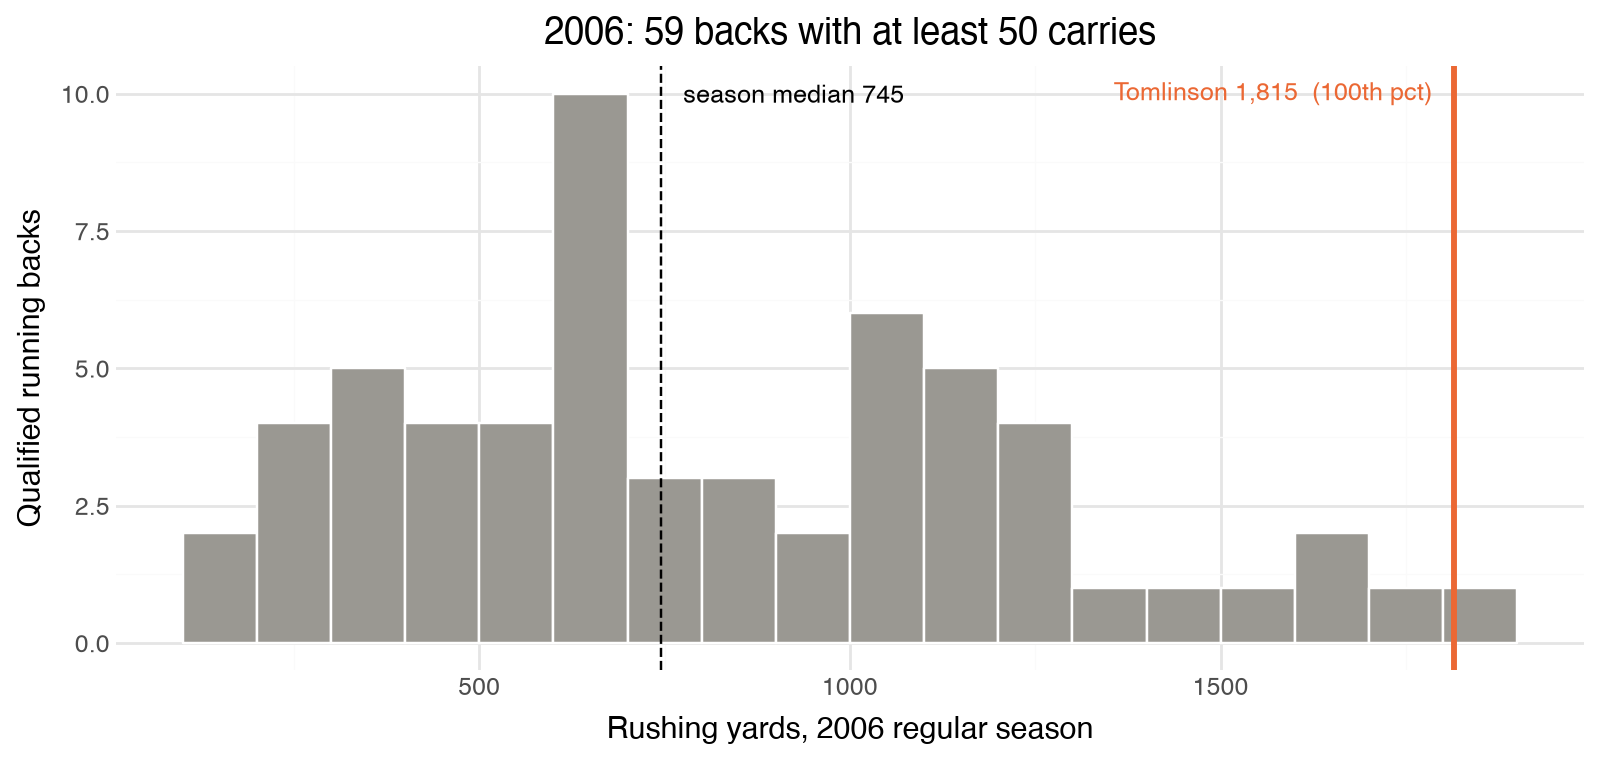

In [10]:
HOF, ACTIVE, OTHER = "#eb6834", "#2a78d6", "#9a9892"

s06 = qualified[qualified["season"] == 2006]
lt  = s06[s06["player_display_name"] == "LaDainian Tomlinson"].iloc[0]
med = s06["season_median"].iloc[0]
top = np.histogram(s06["rushing_yards"], bins=np.arange(0, s06["rushing_yards"].max() + 100, 100))[0].max()

fig1 = (ggplot(s06, aes(x="rushing_yards"))
        + geom_histogram(binwidth=100, boundary=0, fill=OTHER, color="white")
        + geom_vline(xintercept=med, linetype="dashed")
        + annotate("text", x=med + 30, y=top, label=f"season median {med:,.0f}", ha="left", size=9)
        + geom_vline(xintercept=lt["rushing_yards"], color=HOF, size=1.2)
        + annotate("text", x=lt["rushing_yards"] - 30, y=top, label=f"Tomlinson {lt['rushing_yards']:,.0f}  ({lt['pct']:.0f}th pct)",
                   ha="right", color=HOF, size=9)
        + labs(x="Rushing yards, 2006 regular season", y="Qualified running backs",
               title=f"2006: {len(s06)} backs with at least {MIN_CARRIES} carries")
        + theme_minimal() + theme(figure_size=(8, 3.8)))
fig1

**Analysis sentence:** 1,815 yards against a median of 745 — 2.4 times the typical qualified back —
is an exceptional season, and the figure shows it without a league-wide ranking: the comparison is **within the
season**.

### Figure 2 (Q3) — Careers: percentile by career year for two complete Hall of Fame careers and two comparison players
*Statistic: the season percentile each year. Form: **line** plot, career year on the horizontal axis, one line per player.*

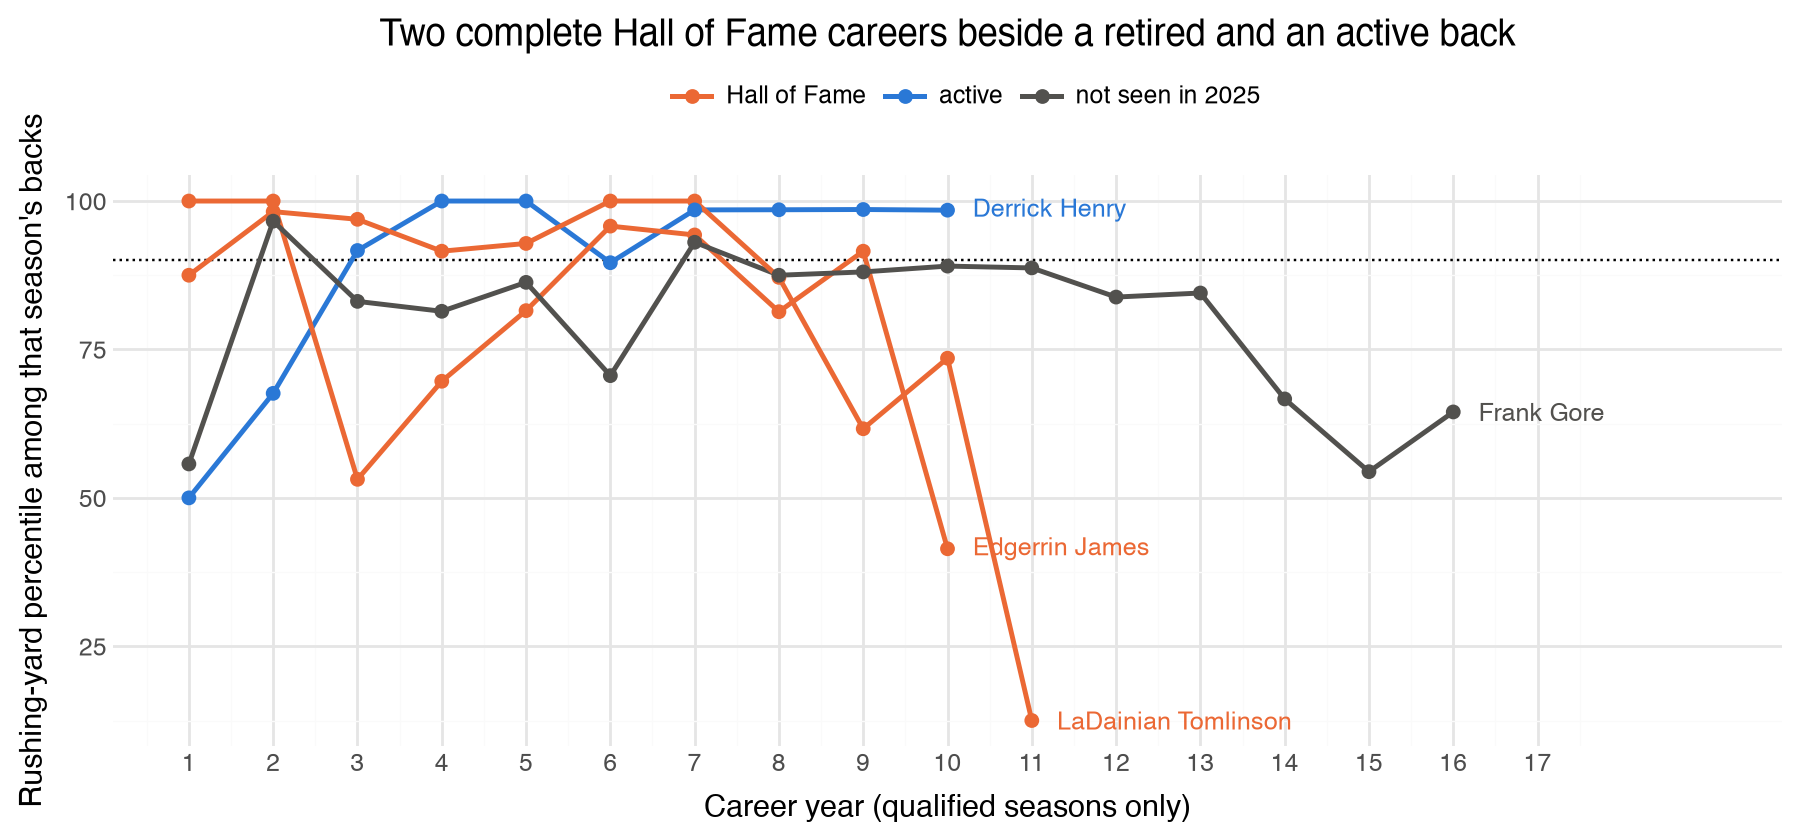

In [11]:
show = ["Edgerrin James", "LaDainian Tomlinson", "Frank Gore", "Derrick Henry"]
paths = qualified[qualified["player_display_name"].isin(show) & (qualified["coverage"] != "partial (pre-1999 seasons missing)")].copy()
paths["who"] = np.select([paths["hof"], paths["season"] == LAST_COMPLETED_SEASON], ["Hall of Fame", "active"], "not seen in 2025")
paths["who"] = paths.groupby("player_display_name")["who"].transform("last")
ends = paths.sort_values("career_year").groupby("player_display_name").tail(1)

fig2 = (ggplot(paths, aes(x="career_year", y="pct", group="player_display_name", color="who"))
        + geom_hline(yintercept=90, linetype="dotted")
        + geom_line(size=1) + geom_point(size=2)
        + geom_text(ends, aes(label="player_display_name"), ha="left", nudge_x=0.3, size=9, show_legend=False)
        + scale_color_manual(values={"Hall of Fame": HOF, "active": ACTIVE, "not seen in 2025": "#52514e"}, name="")
        + scale_x_continuous(breaks=range(1, 18), limits=(1, 19))
        + labs(x="Career year (qualified seasons only)", y="Rushing-yard percentile among that season's backs",
               color="", title="Two complete Hall of Fame careers beside a retired and an active back")
        + theme_minimal() + theme(figure_size=(9, 4.2), legend_position="top"))
fig2

**Analysis sentence:** both complete Hall of Fame careers open at or near the top and stay above the median for a
decade; the dotted line at the 90th percentile shows the difference between a **peak** (a year above it) and
**sustained** performance (many years near it). Gore's line is the length argument; Henry's is the height argument.
Seasons below 50 carries are not plotted — a gap, not a zero.

> **Instructor note.** Say the caveat aloud: of the 8 observable Hall of Famers, only James and Tomlinson have career year 1 in
> the data. The partial careers (Smith, Faulk, Bettis, Martin, Davis, Thomas) are excluded from this figure on purpose;
> their "career year 1" would be 1999, which is false.

### Figure 3 (Q3 and Q4) — Sustained vs peak for every back with at least five qualified seasons
*Statistics: median season percentile (x) and share of seasons at or above the 90th percentile (y). Form: scatter;
Hall of Famers and active players highlighted and labelled.*

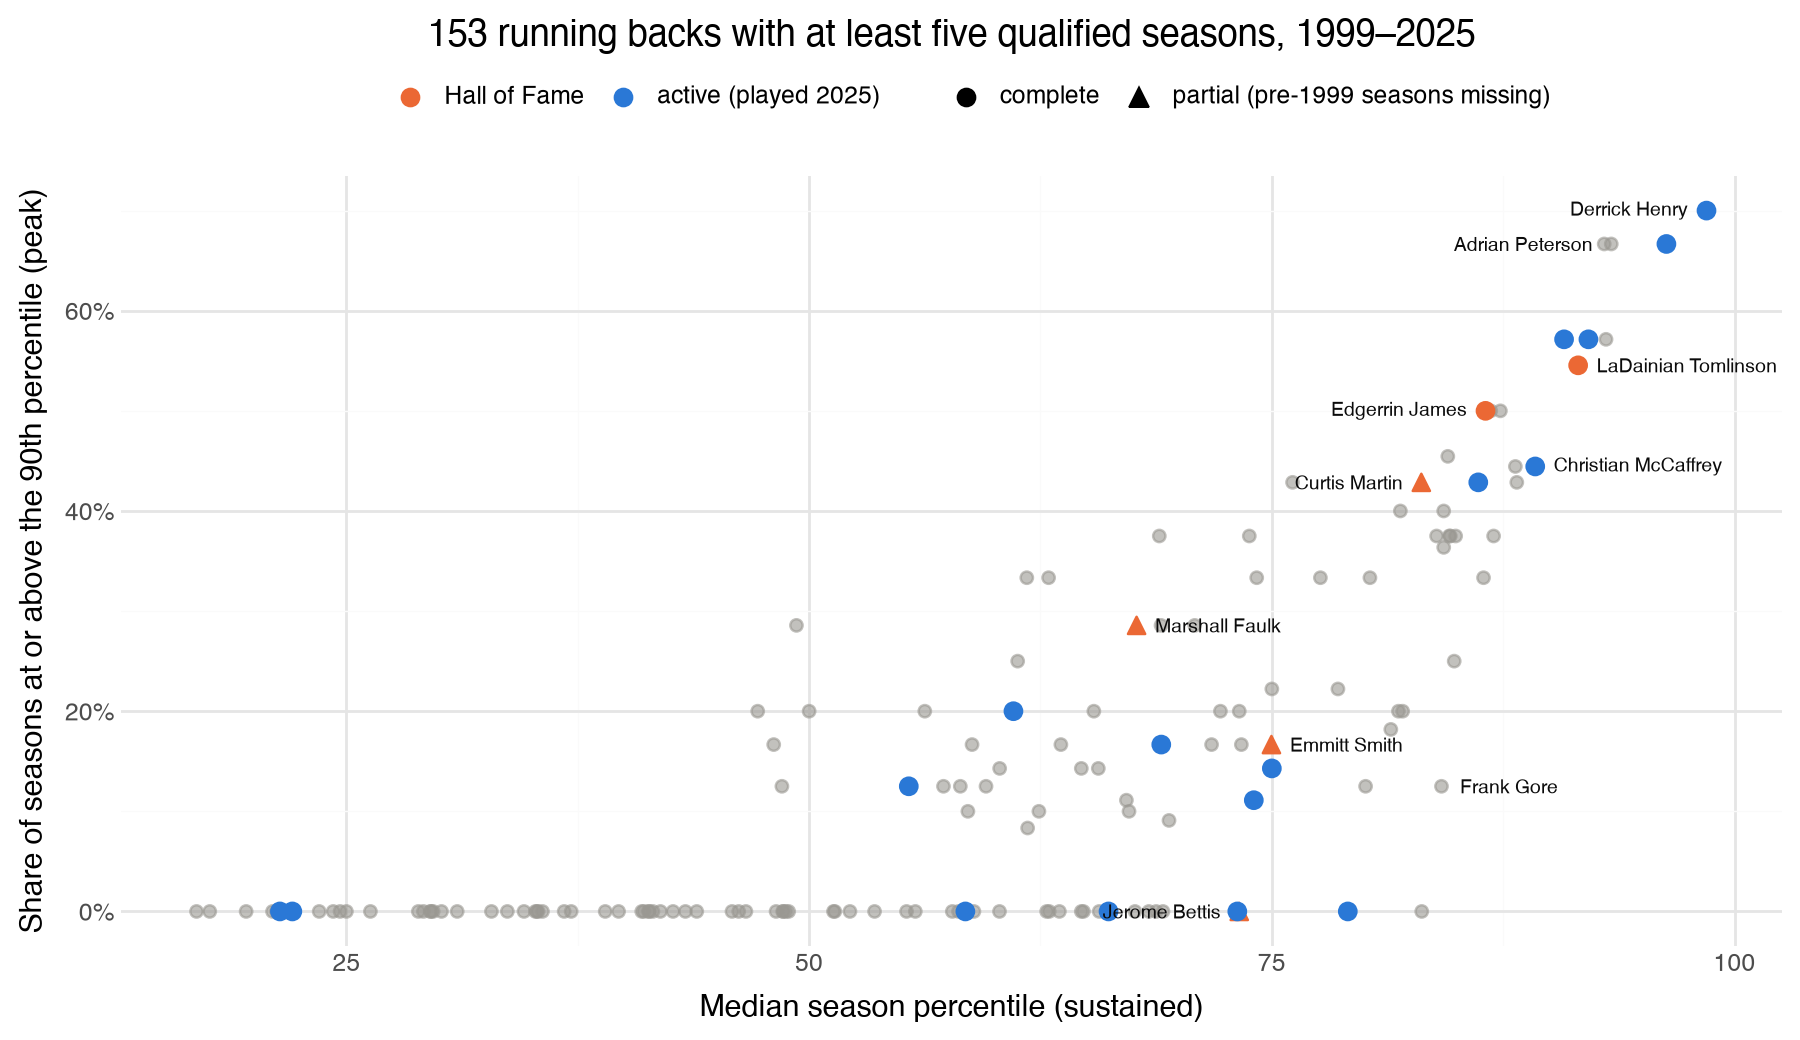

In [12]:
five = career[career["n_qualified"] >= 5].copy()
five["coverage"] = five["coverage"].fillna("complete")
# selective direct labels: the Hall of Famers and four comparison players; names placed left or right to avoid collisions
named = five[five["hof"] | five["player"].isin(["Derrick Henry", "Christian McCaffrey", "Frank Gore", "Adrian Peterson"])]
to_left = named[named["player"].isin(["Adrian Peterson", "Curtis Martin", "Edgerrin James", "Jerome Bettis", "Derrick Henry"])]
to_right = named.drop(to_left.index)

fig3 = (ggplot(five, aes(x="median_pct", y="share_90"))
        + geom_point(five[five["status"] == "not seen in 2025"], color=OTHER, alpha=0.6, size=2)
        + geom_point(five[five["status"] != "not seen in 2025"], aes(color="status", shape="coverage"), size=3)
        + geom_text(to_right, aes(label="player"), size=7, ha="left", nudge_x=1, color="#0b0b0b")
        + geom_text(to_left, aes(label="player"), size=7, ha="right", nudge_x=-1, color="#0b0b0b")
        + scale_color_manual(values={"Hall of Fame": HOF, "active (played 2025)": ACTIVE})
        + scale_shape_manual(values={"complete": "o", "partial (pre-1999 seasons missing)": "^"})
        + scale_y_continuous(labels=lambda l: [f"{100*v:.0f}%" for v in l])
        + labs(x="Median season percentile (sustained)", y="Share of seasons at or above the 90th percentile (peak)",
               color="", shape="", title=f"{len(five)} running backs with at least five qualified seasons, 1999–2025")
        + theme_minimal() + theme(figure_size=(9, 5.2), legend_position="top"))
fig3

**Analysis sentences.** The 6 Hall of Famers with five or more qualified seasons sit toward the upper
right: a median season around the **79th** percentile and a median of **36 %** of seasons at
or above the 90th, against the 61st percentile and 0 % for the other backs with five
or more qualified seasons (most backs never have a 90th-percentile season). The triangles are partial careers:
Bettis and Smith are plotted from their *last* seasons only, which is why they sit low. **Q4:** Henry (10
qualified seasons, median 98th, 70 % at or above the 90th) and McCaffrey (9, 89th, 44 %)
sit with the complete Hall of Fame careers; Gore (16 seasons, median 84th) makes the longevity case from a
lower peak. These are **statistical resemblances, not probabilities of induction**.

In [13]:
cols = ["player", "status", "coverage", "n_qualified", "first_q", "last_q", "median_pct", "max_pct", "share_90", "rush_yards"]
(five[five["status"] != "Hall of Fame"]
     .sort_values("median_pct", ascending=False)
     .head(12)[cols].round(1))

,player,status,coverage,n_qualified,first_q,last_q,median_pct,max_pct,share_90,rush_yards
366,Derrick Henry,active (played 2025),complete,10,2016,2025,98.5,100.0,0.7,13018
440,Jonathan Taylor,active (played 2025),complete,6,2020,2025,96.3,100.0,0.7,7598
197,Adrian Peterson,not seen in 2025,complete,12,2007,2020,93.3,100.0,0.7,14676
231,Arian Foster,not seen in 2025,complete,7,2009,2015,93.1,100.0,0.6,6470
128,Clinton Portis,not seen in 2025,complete,9,2002,2010,93.0,95.7,0.7,9923
413,Nick Chubb,active (played 2025),complete,7,2018,2025,92.1,98.7,0.6,7179
433,Josh Jacobs,active (played 2025),complete,7,2019,2025,90.8,100.0,0.6,7803
375,Christian McCaffrey,active (played 2025),complete,9,2017,2025,89.2,100.0,0.4,7589
387,Dalvin Cook,not seen in 2025,complete,7,2017,2023,88.2,98.7,0.4,6207
373,Ezekiel Elliott,not seen in 2025,complete,9,2016,2024,88.2,100.0,0.4,9130


The candidate table sorts on **one** clearly stated measure and shows the others beside it rather than hiding them
in a single score.

### Figure 4 (Q5) — Does the answer move with the carry threshold?
*Statistic: the Hall of Fame group's median percentile and share ≥ 90 under 25, 50 and 100 carries. Form: a table.*

In [14]:
rows = []
for thr in (25, 50, 100):
    q = rb[(rb["season"] <= LAST_COMPLETED_SEASON) & (rb["carries"] >= thr)].copy()
    q["pct"] = 100 * q.groupby("season")["rushing_yards"].rank(method="max", pct=True)
    c = q.groupby("player_id").agg(hof=("hof", "first"), median_pct=("pct", "median"),
                                   share_90=("pct", lambda s: (s >= 90).mean()))
    rows.append({"min_carries": thr, "peers_per_season": int(q.groupby("season").size().median()),
                 "hof_median_pct": c[c["hof"]]["median_pct"].median(),
                 "hof_share_90": c[c["hof"]]["share_90"].median(),
                 "others_median_pct": c[~c["hof"]]["median_pct"].median()})
pd.DataFrame(rows).round(2)

,min_carries,peers_per_season,hof_median_pct,hof_share_90,others_median_pct
0,25,89,79.28,0.30,38.60
1,50,70,74.98,0.29,39.71
2,100,46,67.46,0.33,40.10


**Analysis sentence:** raising the threshold shrinks the peer group (89 → 70 →
46 backs per season). The Hall of Fame median falls from the 79th to the 67th
percentile, because the seasons that leave the pool were below theirs; the other backs' median barely moves
(39th to 40th) because the seasons that leave were mostly their own. The *ordering* is what to
check: if the same players stay on top under all three rules, the conclusion is stable; the exact percentile never was.

## Part 5 — How do we improve this project?

Work through these in pairs. Each one is a gap in the first version that the SSVA table or the ETV map makes visible.

**5.1 Coverage.** Only 2 of 53 Hall of Fame running backs have complete careers in the data. What does
that do to Q3 and Q4, and what are the two honest ways forward?

**Answer:** Q3 ("what patterns show up across Hall of Fame careers") is being answered from two complete careers and six partial
ones, which is a description of two players, not a pattern. Either (a) obtain a licensed historical source with
stable player ids back to the 1930s, repeat the Extract step and keep nflverse as a check for the overlap years, or
(b) restate the question as a *modern-era* question (1999 onward) and compare active players with the modern cohort
of backs who have been eligible long enough to be judged — which is Q4 with an honest label. Either is fine; mixing
the two silently is not.

**5.2 The comparison group.** The 50-carry rule defines "a running back". Who disappears, and which project question
suffers?

**Answer:** Receiving specialists, blocking fullbacks and injured players drop out, so a receiving-oriented back's best seasons
never get a percentile and Q2 is answered for rushing only. Fix: a second peer group with its own rule (for example
at least 30 targets) and a receiving-yards percentile, then a scrimmage-yards percentile that uses both. Record the
qualifying rule beside every metric, exactly as Figure 4 does for carries.

**5.3 Status.** "Not seen in 2025" is doing a lot of work. What is wrong with it, and what source fixes it?

**Answer:** It mixes retired, injured, unsigned and briefly-benched players, and it cannot tell "eligible but not inducted"
from "not yet eligible" (five full seasons of retirement, plus the Hall's other requirements). The outline's step 9
needs an explicit roster or transactions source with a retirement date per player, and the Hall's current rules,
before any player is labelled a candidate — and even then an eligible player who was not inducted is not a permanent
"no".

**5.4 What the statistics cannot see.** Name two things voters weigh that no column in `rb` contains. Could they be
extracted?

**Answer:** Awards and honors (All-Pro, MVP, rushing titles), postseason performance, team success and narrative (a Super Bowl
run, a record). Awards and playoff statistics are extractable from licensed sources and would be two more E steps
and two more columns in the career table; narrative is not a column, which is one reason the project reports
resemblance rather than probability.

**5.5 Why not fit a classifier now?** We have a labelled column (`hof`) and features. What stops a model from being
the next cell?

**Answer:** Four things. Few positives (eight observable Hall of Famers, two complete), so any model would mostly memorize them.
Leakage in time: the label is known only years after the career ends, so a fair evaluation trains on cohorts that
retired long enough ago to have been judged and tests on later cohorts. Data rights: the source must permit model
use (nflverse does; Pro Football Reference's terms do not). And calibration: a "72 % chance of induction" would be
read as a forecast, which these data cannot support. The descriptive comparison is the right first deliverable.

**5.6 Coherence check.** Go back to the SSVA table in Part 1. Is there a cell in this notebook that does not sit in
one of its rows? Is there a row with no figure?

**Answer:** Every figure maps to a question (1 → Q2, 2 → Q3, 3 → Q3 and Q4, 4 → Q5). Q1 has a table and a count, which is the
right form. What is missing is receiving: Q2 promises "rushing and receiving" and only rushing is shown, so the next
version either adds a receiving percentile to Figures 1 to 3 or edits the question. Either way the table and the
notebook must agree.

---
## For your own final project — the checklist

1. **One paragraph, then numbered questions.** If a question cannot be numbered it is not a question yet.
2. **ETV.** Label every planned step E, T or V. Cache every E with its access date and the code that made it.
   Write every T as a named step with a check (`assert` one row per key; print the counts you expect).
3. **SSVA.** For each question, name the **summary statistic** before choosing the **visualization**, and write the
   **analysis sentence** the figure is supposed to support. One figure per question; colors fixed by entity.
4. **Say what the data cannot answer** (coverage, definitions, status) in the notebook, not in the presentation's
   last slide.
5. **Sensitivity before modelling.** Change the one rule you chose (the threshold, the peer group) and report what
   moves. A model comes after the descriptive version is coherent, and only with data licensed for it.